# Diagnostics

Diagnostics check a fitted model in four steps: training risk, validation-based
stopping, residual structure, and predictive calibration. This page documents
`plot_diagnostics`, the residual and calibration frames, diagnostics for
distributional (LSS) fits, `concurvity()`, and evaluation metrics for
classification and count models.

```{figure} ../figures/mermaid-0e5222fb5c6c.svg
:name: mermaid-0e5222fb5c6c
:alt: Diagnostic workflow from model fit through risk, stopping iteration, residual, and calibration checks to interpretation or model revision.

Diagnosis checks training-risk stabilization, validation-based stopping, residual structure, and predictive calibration before interpretation.
```


In [1]:
import altair as alt
import numpy as np
import polars as pl
import mboostrs as mb
from mboostrs.datasets import bodyfat

bf = bodyfat()
formula = (
    "DEXfat ~ age + waistcirc + hipcirc + elbowbreadth + kneebreadth + "
    "anthro3a + anthro3b + anthro3c + anthro4"
)
fit = mb.glmboost(
    formula,
    data=bf,
    family=mb.Gaussian(),
    control=mb.boost_control(mstop=150, nu=0.1),
)
fit

GLMBoostModel(formula='DEXfat ~ age + waistcirc + hipcirc + elbowbreadth + kneebreadth + anthro3a + anthro3b + anthro3c + anthro4', family=Gaussian, mstop=150)

`plot_diagnostics` draws a dashboard of the risk path, selection frequencies,
fitted against observed values, and residuals:

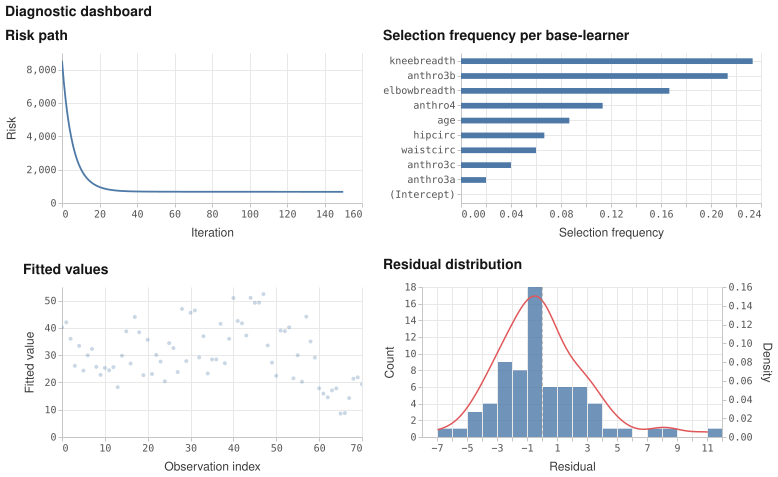

In [2]:
mb.plot.plot_diagnostics(fit)

Read it in this order:

1. Risk should fall quickly and then flatten.
2. A term that identifies rows or leaks information should not dominate the
   selection frequencies.
3. Fitted vs observed should not show obvious curvature.
4. Residuals should be centered and not dominated by a small number of points.

## Residual and calibration tables

The standalone diagnostics helpers return tabular data for custom plots,
notebooks, and tests.

In [3]:
resid = mb.residual_frame(fit, kind="pearson")
resid.head()

index,y,fitted,residual_kind,residual
0,41.68,40.174335,"""pearson""",1.505665
1,43.29,42.049774,"""pearson""",1.240226
2,35.41,36.022004,"""pearson""",-0.612004
3,22.79,26.107188,"""pearson""",-3.317188
4,36.42,33.420317,"""pearson""",2.999683


In [4]:
cal = mb.calibration_frame(fit, xvar="waistcirc", bins=5)
cal

interval,n,x_min,x_max,observed_mean,fitted_mean
1,15,65.0,75.0,18.134,17.818536
2,14,75.3,81.0,24.75,25.651323
3,14,81.0,89.5,29.015714,28.745837
4,14,89.5,102.0,37.901429,37.289461
5,14,102.0,117.0,45.016429,45.334947


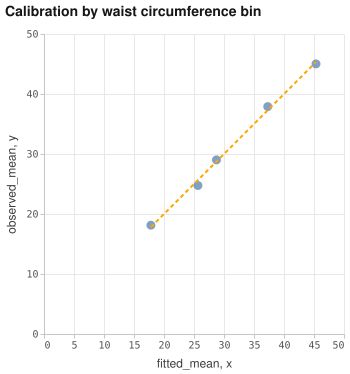

In [5]:
base = alt.Chart(cal).encode(x="fitted_mean", y="observed_mean")
points = base.mark_circle(size=80).encode(
    tooltip=["interval", "n", "x_min", "x_max", "observed_mean", "fitted_mean"]
)
calibration_values = np.concatenate([
    cal["observed_mean"].to_numpy(), cal["fitted_mean"].to_numpy()
])
diag = alt.Chart(pl.DataFrame({
    "x": [calibration_values.min(), calibration_values.max()],
    "y": [calibration_values.min(), calibration_values.max()],
})).mark_line(color="orange", strokeDash=[4, 3]).encode(x="x", y="y")
(points + diag).properties(title="Calibration by waist circumference bin")

Use `outlier_frame` when a residual plot looks dominated by a few cases:

In [6]:
mb.outlier_frame(fit).head()

index,y,fitted,residual_kind,residual
40,62.02,50.964764,"""response""",11.055236
47,60.72,52.405392,"""response""",8.314608
26,40.58,32.59725,"""response""",7.98275
45,42.23,49.194174,"""response""",-6.964174
22,35.4,30.120443,"""response""",5.279557


## Remedies for failed diagnostics

Read each row as symptom $\rightarrow$ likely cause $\rightarrow$ next command to run:

```{list-table}
:header-rows: 1

* - Symptom
  - Likely issue
  - Next move
* - Risk still falling at final iteration
  - `mstop` grid is too short
  - Increase `mstop` and tune with `cvrisk`
* - Validation risk rises early
  - Overfitting after a small number of steps
  - Use `with_mstop(k)` or `fit[:k]`
* - Residuals curve against a predictor
  - Missing nonlinear effect
  - Try `gamboost` with `bbs()` or `bmono()`
* - Residual spread changes with fitted value
  - Mean-only model is missing scale structure
  - Try `glmboostLSS` or `gamboostLSS`
* - Binary probabilities are miscalibrated
  - Wrong link scale, missing nonlinear terms, or too much shrinkage
  - Inspect `type="response"` predictions and calibration bins
```

## Distributional diagnostics

An LSS fit supplies row-specific distribution parameters. When its family
provides CDF and quantile functions, these parameters give predictive
intervals, probability integral transform (PIT) values and randomized quantile residuals. Binned residual
moments help locate covariate ranges where the fitted distribution is
inadequate; parameter predictions show whether its mean or spread varies
there. A mean predictor alone does not determine these distributional checks.

## Residual gallery across families

Pearson residuals are defined the same way for every family
(`(y - fitted) / sqrt(variance(fitted))`) but look qualitatively different
because each family's variance function is different. Fit the same
predictor against Gaussian, Binomial, and Poisson responses and compare:

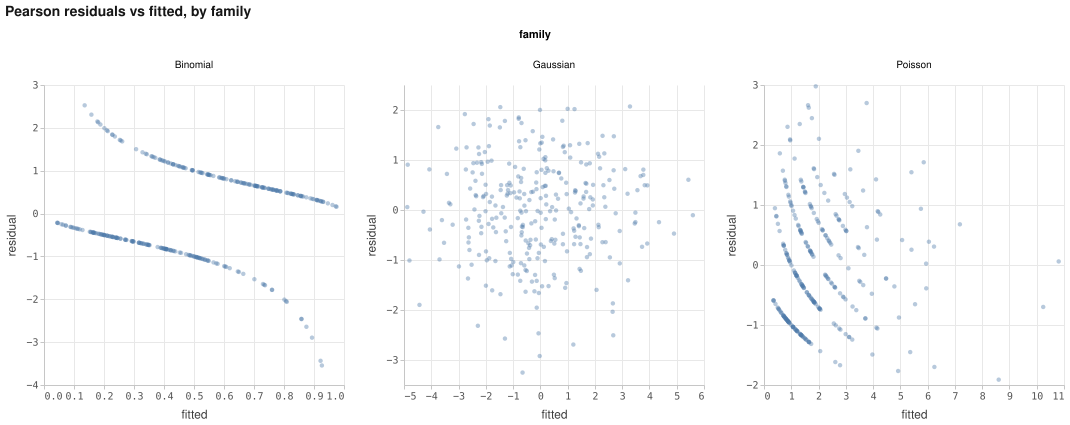

In [7]:
rng = np.random.default_rng(5)
n_gallery = 300
x_gallery = rng.normal(size=n_gallery)

y_gauss = 2 * x_gallery + rng.normal(size=n_gallery)
fit_gauss = mb.glmboost("y ~ x", data={"x": x_gallery, "y": y_gauss},
                        family=mb.Gaussian(), control=mb.boost_control(150, 0.1))

p_binom = 1 / (1 + np.exp(-1.5 * x_gallery))
y_binom = (rng.uniform(size=n_gallery) < p_binom).astype(float)
fit_binom = mb.glmboost("y ~ x", data={"x": x_gallery, "y": y_binom},
                        family=mb.Binomial(), control=mb.boost_control(150, 0.1))

mu_pois = np.exp(0.5 + 0.7 * x_gallery)
y_pois = rng.poisson(mu_pois).astype(float)
fit_pois = mb.glmboost("y ~ x", data={"x": x_gallery, "y": y_pois},
                       family=mb.Poisson(), control=mb.boost_control(150, 0.1))

gallery_rows = []
for name, gfit in [("Gaussian", fit_gauss), ("Binomial", fit_binom), ("Poisson", fit_pois)]:
    r = mb.residual_frame(gfit, kind="pearson").with_columns(
        pl.lit(name).alias("family")
    )
    gallery_rows.append(r)
gallery_frame = pl.concat(gallery_rows, how="vertical")

alt.Chart(gallery_frame).mark_circle(opacity=0.4, size=20).encode(
    x="fitted:Q", y="residual:Q", column="family:N"
).resolve_scale(x="independent", y="independent").properties(
    title="Pearson residuals vs fitted, by family"
)


Gaussian residuals scatter with constant spread across fitted values (the
variance function is constant). Binomial residuals cluster into two curved
bands (one per outcome), typical of binary responses on the response scale.

Poisson residuals need care because they are *Pearson* residuals. Dividing by
$\sqrt{\operatorname{Var}} = \sqrt{\mu}$ removes the fanning that a raw
Poisson residual plot shows, so on a well-specified fit the spread is **flat and
close to 1** at every fitted value. Overdispersion raises the overall scale of
that spread and leaves it flat. Measured on 300 observations:

| | spread of Pearson residuals |
|---|---|
| well-specified Poisson | flat across fitted quartiles, sd $\approx 0.94$ overall |
| overdispersed (var/mean $= 3.8$), same model | sd $\approx 1.45$ overall |

An sd near 1 indicates a correct Poisson fit, and an sd meaningfully above 1
indicates overdispersion (see [](families.ipynb) for the `NBinomial`
alternative). A *raw* residual plot would fan out with $\mu$; the Pearson
residual plot does not.

In [8]:
from mboostrs.datasets import india

ind = india().sample(n=800, seed=0)
lss = mb.glmboostLSS(
    "stunting ~ cbmi + cage + mbmi + mage",
    data=ind,
    family=mb.GaussianLSS(),
    control=mb.boost_control(mstop=80, nu=0.1),
)
lss

LSSModel(family=GaussianLSS, params=['mu', 'sigma'], mstop=80)

`predict_all` returns the fitted distribution parameters for every row:

In [9]:
lss.predict_all(output="auto").head()

index,y,mu,sigma
0,0.95,-0.838204,1.461204
1,-2.56,-2.272761,1.431303
2,-0.94,-0.672004,1.431888
3,0.46,-2.382442,1.608758
4,-0.73,-1.165725,1.445089


Prediction intervals combine the fitted location and scale. For miscoverage
`alpha=1-level`, the central interval score is width plus `2/alpha` times
the distance below or above a missed bound. Width and misses therefore enter
one proper score (a scoring rule minimized by the true interval) rather than rewarding a narrow interval that covers little.

In [10]:
pi = lss.prediction_interval(level=0.8)
pi.head()

index,lower,median,upper,level,lower_prob,upper_prob
0,-2.710811,-0.838204,1.034404,0.8,0.1,0.9
1,-4.107049,-2.272761,-0.438473,0.8,0.1,0.9
2,-2.507042,-0.672004,1.163034,0.8,0.1,0.9
3,-4.444149,-2.382442,-0.320735,0.8,0.1,0.9
4,-3.017681,-1.165725,0.68623,0.8,0.1,0.9


In [11]:
interval_quality = mb.interval_metrics(
    ind["stunting"], pi["lower"], pi["upper"], level=0.8,
)
pl.DataFrame([interval_quality])

nominal_coverage,empirical_coverage,lower_miss_rate,upper_miss_rate,mean_width,mean_interval_score,weight_total,n,score_definition
0.8,0.805,0.1025,0.0925,3.79627,5.276958,800.0,800,"""central_interval_score"""


`evaluate_distribution` combines density or mass, log score, deviance, randomized PIT,
central interval scores, and requested strict exceedance checks from one parameter
prediction. Gaussian LSS also has an analytical continuous ranked probability score (CRPS), which scores the whole predictive distribution against the observed value; lower is better. `data_role` is mandatory:
`"external"` declares that outcomes were excluded from fitting, tuning, preprocessing
and specification choices; `"training"` labels a diagnostic without a future-performance
claim. An already-fitted object cannot verify the external-data declaration.


mean_log_score,zero_density_weight,mean_deviance,pit_mean,pit_variance,weight_total,mean_crps
1.809212,0.0,3.618424,0.4976,0.079716,800.0,0.826463


nominal_coverage,empirical_coverage,lower_miss_rate,upper_miss_rate,mean_width,mean_interval_score,weight_total,n,score_definition
0.8,0.805,0.1025,0.0925,3.79627,5.276958,800.0,800,"""central_interval_score"""
0.95,0.9425,0.025,0.0325,5.805894,7.307129,800.0,800,"""central_interval_score"""


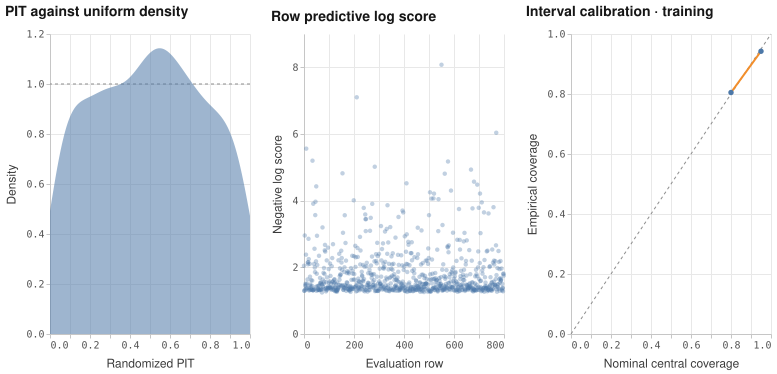

In [12]:
distribution_quality = mb.evaluate_distribution(
    lss, ind, response="stunting", data_role="training",
    levels=(0.8, 0.95), thresholds=(30,), random_state=1,
)
display(pl.DataFrame([dict(distribution_quality.metrics)]))
display(distribution_quality.interval_frame(output="polars"))
mb.plot.plot_distribution_evaluation(distribution_quality)


These rows were used to fit the model, so their empirical coverage and interval score
diagnose the fitted distribution but do not estimate future-outcome performance. A held-out
or conformal evaluation needs a split matching deployment.

Quantile residuals should look standard normal when the fitted
distribution is adequate:

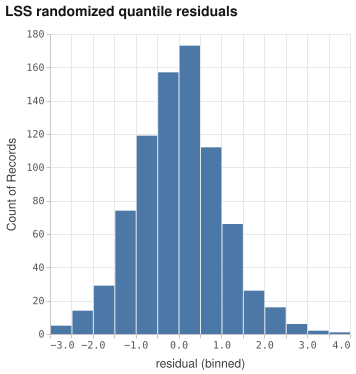

In [13]:
qres = lss.residual_frame(kind="quantile")
alt.Chart(qres).mark_bar().encode(
    x=alt.X("residual", bin=alt.Bin(maxbins=30)),
    y="count()",
).properties(title="LSS randomized quantile residuals")

Q-statistics summarize residual moments by a covariate. Large mean shifts or
variance changes by bin are a sign that the model missed structure.

In [14]:
lss.q_stats(xvar="mage", n_intervals=6)

interval,xvar,x_min,x_max,n,mean,variance,skewness,kurtosis
1,"""mage""",13.0,20.0,134,-0.043229,1.215732,0.42951,0.032836
2,"""mage""",20.0,22.0,134,-0.039755,0.80256,-0.307441,0.391123
3,"""mage""",22.0,24.0,133,0.038586,0.938744,-0.259772,0.110002
4,"""mage""",24.0,26.0,133,0.126989,0.929843,0.308219,0.443491
5,"""mage""",26.0,30.0,133,-0.101694,1.000338,0.132581,-0.105972
6,"""mage""",30.0,43.0,133,0.018784,1.103512,0.35886,0.730249


`worm_plot` is the visual companion to `q_stats`: a detrended normal QQ-plot
(R's `gamlss::wp()`) of the quantile residuals, binned by a covariate. Each
panel plots `residual − theoretical_quantile` against the theoretical quantile,
so a flat cloud around zero means the fitted distribution matches the data in
that bin; a tilt or curve flags a location, scale, or shape mismatch.

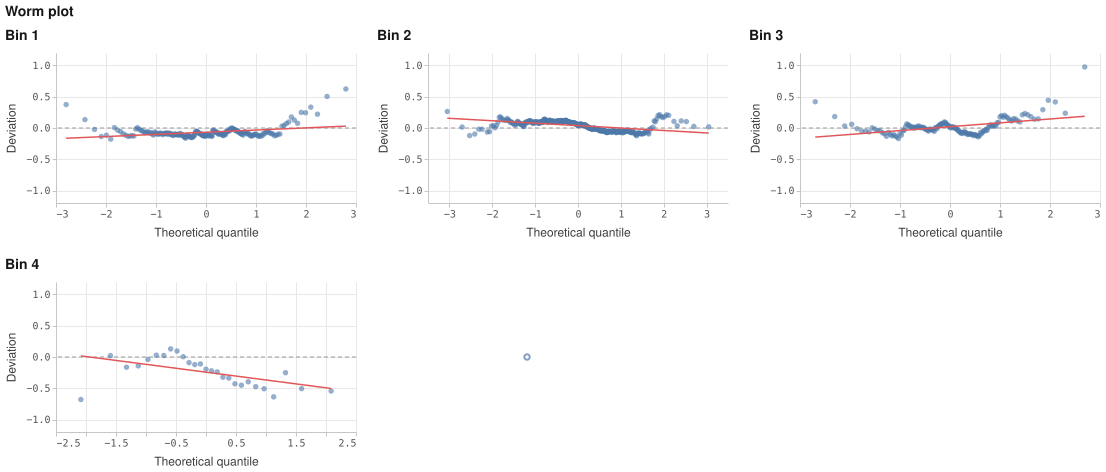

In [15]:
lss.worm_plot(xvar="mage", n_intervals=4)

### Distribution overlays, centile fans, and deviance profiles

A density overlay compares the observed marginal distribution with the
average of every row-specific fitted distribution. It does not evaluate one
density at average parameters, which would be wrong when scale or shape
varies across rows. For counts the same function compares empirical and
fitted probability masses. The observed continuous curve is a kernel-density
estimate, so its small-scale shape depends on bandwidth.

A centile fan orders row-specific predictive quantiles by a numeric covariate.
The shaded regions are central prediction bands, which show the spread of predicted individual outcomes. They are not confidence intervals for the centile curves. `split_by=` makes panels from one fitted model; it does not
refit a separate model per group. A deviance profile then bins the joint LSS
deviance along the same covariate. Because the likelihood is joint across
parameters, that profile localizes poorly fitted observations but does not
attribute loss to one parameter or term.


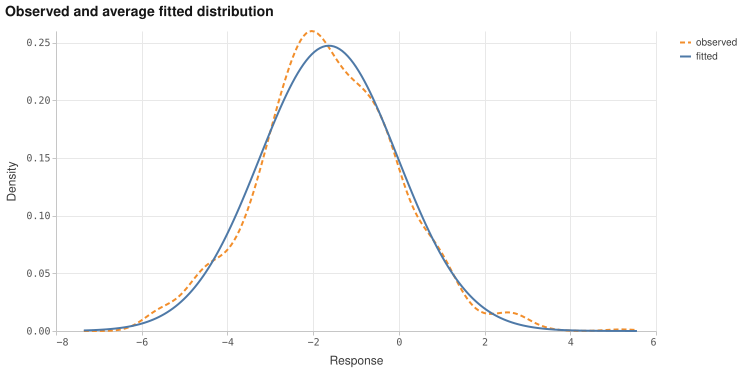

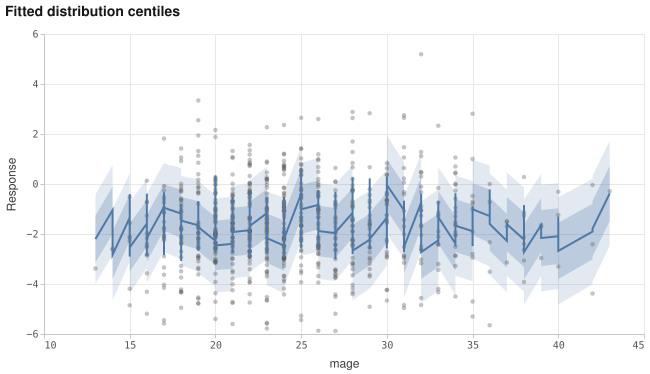

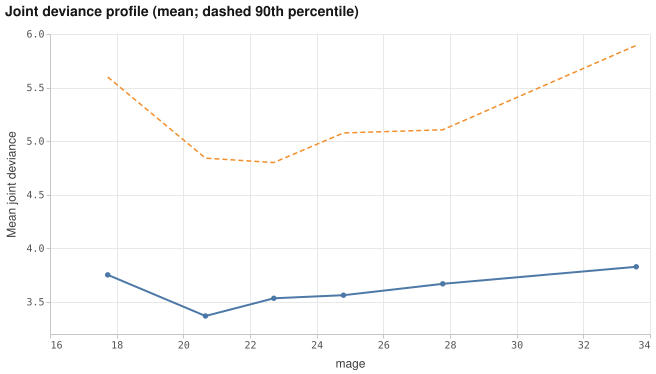

In [16]:
display(lss.plot_density())
display(lss.plot_centile_fan("mage", probs=[0.1, 0.25, 0.5, 0.75, 0.9]))
display(lss.plot_deviance_profile(xvar="mage", bins=6))

## Concurvity of smooth terms: `concurvity()`

`concurvity()` measures how far one smooth term's function space reaches
into another's, the additive-model analogue of collinearity. When it is
high, the partial effects are not separately identified: the same fit can
be redistributed between the terms, so their shapes, intervals and the
selection that chose them are unstable {cite}`wood2017generalized`. Use
it when two partial effects look like versions of one curve, or when
a formula offers several measurements of the same underlying quantity.


In [17]:
gfit = mb.gamboost(
    "DEXfat ~ bbs(age, knots=8) + bbs(waistcirc, knots=8)"
    " + bbs(hipcirc, knots=8) + bbs(anthro3c, knots=8)",
    data=bf,
    family=mb.Gaussian(),
    control=mb.boost_control(mstop=400, nu=0.1),
)
pl.DataFrame(gfit.concurvity(output="records"))


term,worst,observed,estimate
"""bbs(age)""",0.870896,0.501438,0.466629
"""bbs(waistcirc)""",0.946884,0.876206,0.635875
"""bbs(hipcirc)""",0.893749,0.830879,0.649898
"""bbs(anthro3c)""",0.92107,0.813753,0.615293


Each row measures one term against the rest of the model and reports three
values from 0 (the term's space is orthogonal to the others) to 1 (its
functions lie in their span). `worst` is the largest fraction of any term
function the rest can reproduce; `observed` is that fraction at the fitted
coefficients, NaN when the term was never selected; `estimate` averages
over coefficient directions. `worst` is a pessimistic bound, because rich
bases share their low-frequency directions even between unrelated
covariates, so compare rows against each other and rank pairs by
`observed`. Waist and hip circumference, two girth measurements of the
same body, reach the highest values, as expected for two measurements of one
quantity.

`pairwise=True` reports one row per ordered pair, mgcv's pairwise
matrices: `term` is measured against `against` alone, and no intercept is
involved.


In [18]:
pairs = pl.DataFrame(gfit.concurvity(pairwise=True, output="records"))
pairs.sort("worst", descending=True).head(6)


term,against,worst,observed,estimate
"""bbs(waistcirc)""","""bbs(hipcirc)""",0.828848,0.765987,0.386545
"""bbs(hipcirc)""","""bbs(waistcirc)""",0.828848,0.772226,0.427713
"""bbs(anthro3c)""","""bbs(waistcirc)""",0.718524,0.655443,0.322904
"""bbs(waistcirc)""","""bbs(anthro3c)""",0.718524,0.548323,0.268735
"""bbs(hipcirc)""","""bbs(anthro3c)""",0.689666,0.517599,0.261953
"""bbs(anthro3c)""","""bbs(hipcirc)""",0.689666,0.595895,0.324138


Two properties limit how the values are read. Each term is first reduced by the
constant direction, the way mgcv's sum-to-zero constraints reduce its
smooths, so the values describe the non-constant parts of each basis, and
a term that is constant after the reduction reports NaN. `worst`
saturates at 1 for every pair once the combined basis dimension approaches
the number of rows: with 71 women, the four bases `bbs(age)`, `bbs(waistcirc)`, `bbs(hipcirc)` and `bbs(anthro3c)` are held at
`knots=8` for exactly that reason. Trees and `%O%` learners (`%O%` is the Kronecker construction that shares one term across the classes of a multinomial model), which expose
no function-space basis for this measure, are omitted from the table.

The study [](../cases/concurvity_girth.ipynb) works a specification
decision from this table on the same data. For the penalized refit,
`gam_refit(model).concurvity()` reports the same three measures from the
refit's model matrix, and `term_report(concurvity=True)` carries them into
the search report.

`glmboost()` models expose the same method, where a term is one column
and the table is the collinearity of the centered columns: `worst` is
the column's squared-multiple-correlation with the intercept and the
other columns, and the three measures coincide up to rounding because a
single column has one coefficient direction. The formula's intercept is
constant after centering, so it reports NaN, and every pairwise row
naming it too.


## Classification metrics: probability, ranking and utility

A probability model has three distinct evaluation questions. The Brier score (the mean squared difference between the predicted probability and the 0/1 outcome) and the log loss (the negative mean log of the probability given to the observed outcome) score
the numerical probabilities. ROC curves (true-positive rate against false-positive rate) and precision–recall curves score rankings as a
threshold varies. A decision threshold needs the utility of true negatives, false
positives, false negatives, and true positives in one application-specific unit. AUC
does not determine that utility and can remain unchanged when probabilities become
miscalibrated.

`evaluate_specification` retains out-of-fold probabilities and weights. Its classification
methods compute weighted confusion summaries, exact empirical ROC/AUC, step-integrated
average precision, and threshold utility from those held-out rows. Reliability bins use
a Wilson interval with Kish effective sample size only for the IID-row task; grouped and
temporal evaluations omit a row-IID interval.

For `Multinomial`, use `score="log_loss"` or `score="brier"` with stratified
folds. Every training fold must contain every class so probability-column labels cannot
change between fits. `multiclass_metrics`, `multiclass_confusion_frame`, and
`multiclass_calibration_frame` retain the original labels; classwise calibration is
descriptive until simultaneous or dependence-aware uncertainty is specified.


threshold,true_positive_weight,false_positive_weight,false_negative_weight,true_negative_weight,prevalence,accuracy,sensitivity,specificity,precision,f1,brier,log_loss
0.5,189.0,88.0,72.0,151.0,0.522,0.68,0.724138,0.631799,0.68231,0.702602,0.209761,0.607555


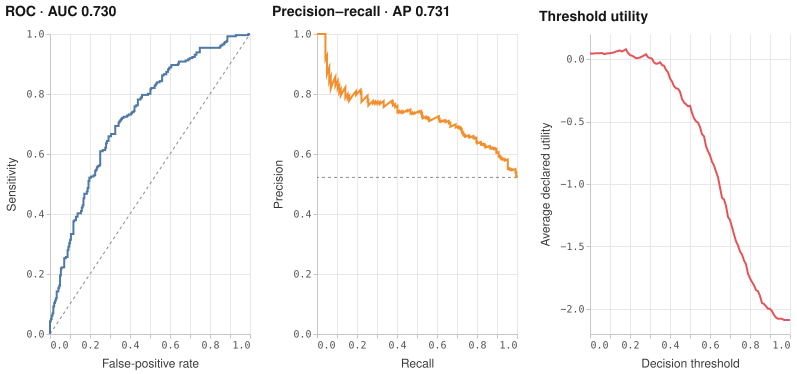

In [19]:
rng = np.random.default_rng(31)
n_class = 500
score_x = rng.normal(size=n_class)
event_probability = 1 / (1 + np.exp(-score_x))
event = rng.binomial(1, event_probability)
classification_data = pl.DataFrame({"score_x": score_x, "event": event})
classification_evaluation = mb.evaluate_specification(
    "bols(score_x)", classification_data, "event", family=mb.Binomial(),
    folds=5, mstop=100, score="log_loss",
)
display(pl.DataFrame([classification_evaluation.classification_metrics(threshold=0.5)]))
mb.plot.plot_classification_evaluation(
    classification_evaluation, utility=(0, -1, -4, 1),
)


## Count metrics and exposure

`EvaluationResult.count_metrics` requires finite nonnegative integer outcomes and
response-scale predictions. With exposure (the time or unit size over which each count is observed; it is not an offset in the fit), `prediction_quantity="count"` reads a
prediction as the expected count for that row's exposure and derives a rate; `"rate"`
multiplies the prediction by exposure before evaluating count loss. It reports count and
rate errors, aggregate observed/predicted rates, and Poisson deviance and log score.

This declaration does not add an exposure offset to the fitted model. Per-observation
offsets remain unsupported, so a fitted count model must already have a defensible way to
produce expected counts or rates for the supplied exposure. The evaluator refuses to infer
that meaning from the numerical prediction.


## Diagnostic support by family

Not every family has every distribution function yet. Check support before
building a workflow around CDF, quantile, simulation, or deviance increments:

In [20]:
caps = mb.family_capabilities(output="polars")
caps.filter(
    pl.col("name").is_in(["GaussianLSS", "NBinomialLSS", "ZIPoLSS", "JSULSS"])
).select(["name", "cdf", "quantile", "simulate", "deviance_increment", "diagnostics"])

name,cdf,quantile,simulate,deviance_increment,diagnostics
"""GaussianLSS""","""yes""","""yes""","""yes""","""yes""","""partial"""
"""JSULSS""","""yes""","""yes""","""planned""","""yes""","""yes"""
"""NBinomialLSS""","""yes""","""yes""","""yes""","""yes""","""partial"""
"""ZIPoLSS""","""yes""","""yes""","""yes""","""yes""","""partial"""


## See also

- [](model_selection.ipynb) for cross-validated risk and `mstop`.
- [](inference.ipynb) for summaries, confidence intervals, and variable importance.
- [](gamboostlss.ipynb) for distributional boosting workflows.
- [](plotting_serialization.ipynb) for the full plotting gallery.